In [25]:
import numpy as np 
import matplotlib.pyplot as plt
import xarray as xr
import month_season_utils as msu

In [26]:
data = xr.open_dataset("ERA5_T2m_1940-2025.nc")
temp = data["var167"]

In [27]:
temp.sel(lat=slice(-5,5),lon=slice(190,240))

<xarray.DataArray 'var167' (time: 31259, lat: 4, lon: 21)> Size: 11MB
[2625756 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 250kB 1940-01-01T11:30:00 ... 2025-07-31T1...
  * lat      (lat) float64 32B -3.75 -1.25 1.25 3.75
  * lon      (lon) float64 168B 190.0 192.5 195.0 197.5 ... 235.0 237.5 240.0
Attributes:
    code:     167
    table:    128

ONI with a fixed climatology

In [28]:
# Subset temperatures over Nino 3.4 region
nino34_temp = temp.sel(lat=slice(-5,5),lon=slice(190,240))

# Weights for spatial average
weights = np.cos(np.deg2rad(nino34_temp.lat))
nino34_temp_weighted = nino34_temp.weighted(weights)

# Spatially averaged daily mean temperature over Nino 3.4 region
daily_mean = nino34_temp_weighted.mean(dim=("lat","lon"))

# Monthly mean temperature
monthly_mean = daily_mean.resample(time="MS").mean()

# Monthly climatology
climatology = monthly_mean.sel(time=slice("1991","2020")).groupby("time.month").mean(dim="time")

# Temperature anomalies
anomalies = monthly_mean.groupby("time.month") - climatology

# ONI
oni = anomalies.rolling(time=3,center=True,min_periods=3).mean()
oni = oni.dropna(dim="time")

ONI with a moving climatology

In [29]:
# Subset temperatures over Nino 3.4 region
nino34_temp = temp.sel(lat=slice(-5,5),lon=slice(190,240))

# Weights for spatial average
weights = np.cos(np.deg2rad(nino34_temp.lat))
nino34_temp_weighted = nino34_temp.weighted(weights)

# Spatially averaged daily mean temperature over Nino 3.4 region
daily_mean = nino34_temp_weighted.mean(dim=("lat","lon"))

# Monthly mean temperature
monthly_mean = daily_mean.resample(time="MS").mean()

# Divide years into blocks of 5, represented by the number in the array `block`, and assign them to monthly means
block = (monthly_mean.time.dt.year - 1) // 5
monthly_mean = monthly_mean.assign_coords(block=("time",block.values))

# Moving window for baseline period
window = 30

# First and last year in the dataset
y0, y1 = int(monthly_mean.time.dt.year.min()), int(monthly_mean.time.dt.year.max())

def block_anomaly(x):
    start = int(x.block[0]) * 5 + 1         # first year of the block the input is in 
    b0 = start - window // 2                # beginning of the baseline period
    b0 = max(y0, min(b0, y1 - window + 1))  # beginning of the baseline period made sure that it stays within the dataset
    
    # Climatology of the block
    climatology = monthly_mean.sel(time=slice(str(b0),str(b0+window-1))).groupby("time.month").mean(dim="time")

    return x.groupby("time.month") - climatology

# Temperature anomalies
anomalies = monthly_mean.groupby("block").map(block_anomaly)

# ONI
oni = anomalies.rolling(time=3,center=True,min_periods=3).mean().dropna(dim="time")
oni.name = "ONI"

<>:5: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:5: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
/tmp/ipykernel_40166/3083643895.py:5: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  ax.set_ylabel("Oceanic Nino Index ($^{\circ}C$)")


Text(0.5, 1.0, 'Time series of Oceanic Nino Index calculated from ERA5 daily 2m surface air temperature')

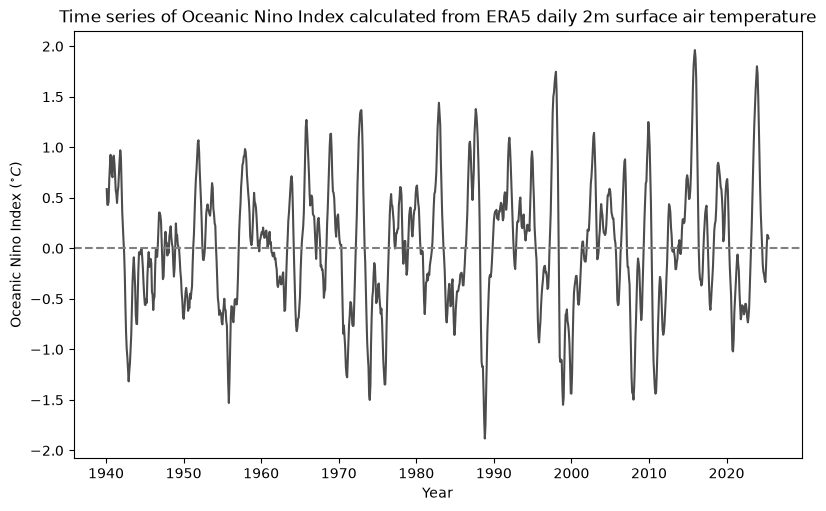

In [30]:
fig, ax = plt.subplots(figsize=(8,5),layout="constrained")

oni.plot.line(ax=ax,color='k',alpha=0.7)
ax.set_xlabel("Year")
ax.set_ylabel("Oceanic Nino Index ($^{\circ}C$)")
ax.axhline(0,ls='dashed',color='gray')
ax.set_title("Time series of Oceanic Nino Index calculated from ERA5 daily 2m surface air temperature")

In [31]:
print(oni.std().values)

0.6346594915235854


In [32]:
rng = np.random.default_rng(42)
n = len(oni)
white_noise = rng.standard_normal(n) * oni.std().values

(0.0, 40.0)

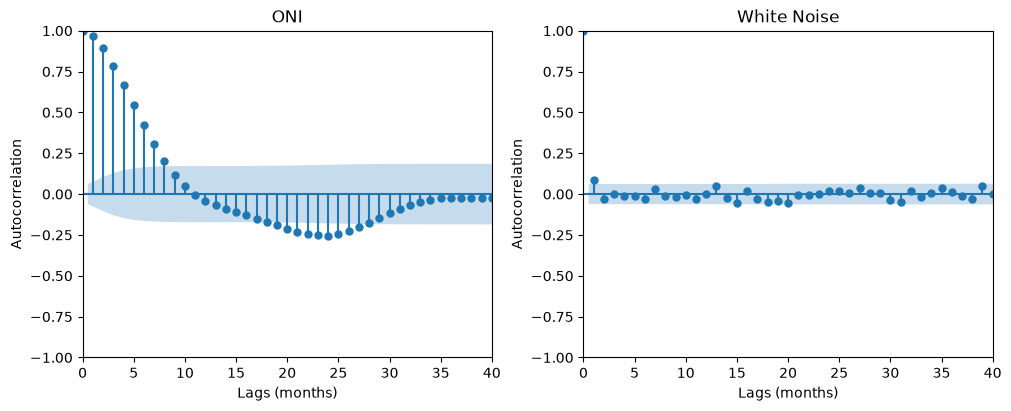

In [33]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(figsize=(10,4),ncols=2, layout='constrained')
ax1 = axes[0]
ax2 = axes[1]

plot_acf(oni,lags=40,ax=ax1)
plot_acf(white_noise,lags=40,ax=ax2)
ax1.set_xlabel('Lags (months)')
ax1.set_ylabel('Autocorrelation')
ax1.set_title('ONI')
ax1.set_xlim(0,40)

ax2.set_xlabel('Lags (months)')
ax2.set_ylabel('Autocorrelation')
ax2.set_title('White Noise')
ax2.set_xlim(0,40)

# plt.savefig("./figs/oni_acf_moving_baseline_40lags.png")

(0.0, 40.0)

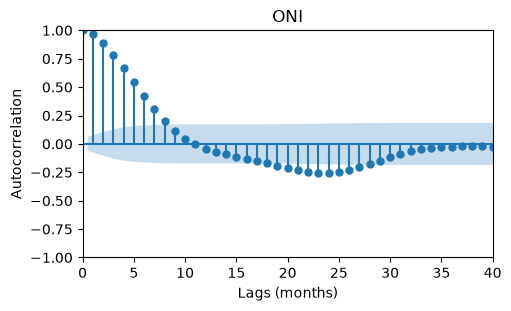

In [34]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(figsize=(5,3), layout='constrained')

plot_acf(oni,lags=40,ax=axes)
axes.set_xlabel('Lags (months)')
axes.set_ylabel('Autocorrelation')
axes.set_title('ONI')
axes.set_xlim(0,40)


# plt.savefig("./figs/oni_acf_moving_baseline_40lags.png")

In [35]:
def hindcast(oni,target_month,lead_time,skills=True):
    target = oni.sel(time=oni.time.dt.month == target_month)
    persist = oni.shift(time=lead_time).sel(time=target.time)

    valid = target.notnull() & persist.notnull()
    target = target.where(valid, drop=True)
    persist = persist.where(valid, drop=True)
    climatology = xr.full_like(target, target.mean().item())

    if skills == True:
        r = xr.corr(target,persist,dim="time").item()
        rmse_p = float(np.sqrt(((persist - target) ** 2).mean()))
        rmse_c = float(np.sqrt(((climatology - target) ** 2).mean()))
        return target, persist, climatology, r, rmse_p, rmse_c

    else:
        return target, persist, climatology

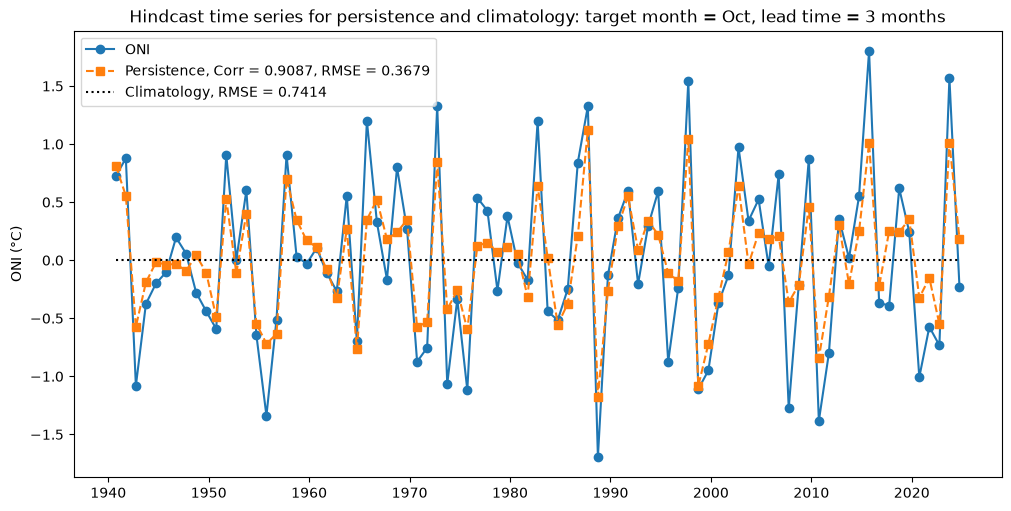

In [36]:
target_month = 10
lead_time = 3

target, persist, climatology, r, rmse_p, rmse_c = hindcast(oni,target_month=target_month,lead_time=lead_time)

fig, ax = plt.subplots(figsize=(10, 5),layout="constrained")
ax.plot(target.time, target, "o-", label="ONI")
ax.plot(target.time, persist, "s--", label=f"Persistence, Corr = {r:.4f}, RMSE = {rmse_p:.4f}")
ax.plot(target.time, climatology, "k:", label=f"Climatology, RMSE = {rmse_c:.4f}")
ax.set_ylabel("ONI (°C)")
ax.set_title(f"Hindcast time series for persistence and climatology: target month = {msu.month_number_to_name(target_month)}, lead time = {lead_time} months")
ax.legend()